Feature screening for ticket #139: what data each candidate has.

Chart 1: nights without a price, by month, stacked by year.
"Missing" = a night with no rate, or a night that is not in the table at all.

In [101]:
# imports
import calendar

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import select

from foresight.database.models.booking import Booking, BookingCancellation
from foresight.database.models.hotel import DailyPerformance, RoomType
from foresight.database.session import async_session_factory
from foresight.repository import hotel as hotel_repo
from foresight.services.hotels.hotel import get_hotel

HOTEL_ID = 1
SURFACE, GRID = "#fcfcfb", "#e5e4e0"
# One blue per year, light (oldest) to dark (newest).
YEAR_COLORS = {
    2022: "#86b6ef",
    2023: "#5598e7",
    2024: "#2a78d6",
    2025: "#1c5cab",
}


async def load_raw_nights():
    """Every night, priced or not (the loader the model uses drops unpriced ones)."""
    async with async_session_factory() as session:
        hotel = await get_hotel(session, HOTEL_ID)
        return await hotel_repo.list_nights(session, hotel.id, start=None, end=None)

In [102]:
# Load raw nights and identify missing prices and plots them per month
nights = pd.DataFrame(await load_raw_nights())  # noqa: F704
rate = pd.Series(nights["rate"], dtype=float)
priced = pd.DatetimeIndex(pd.to_datetime(nights.loc[rate > 0, "stay_date"]))

every_night = pd.date_range(nights["stay_date"].min(), nights["stay_date"].max())
missing = every_night.difference(priced)
print(
    f"{len(missing)} nights without a price, {every_night[0].date()} to "
    f"{every_night[-1].date()}"
)

185 nights without a price, 2022-01-01 to 2026-10-12


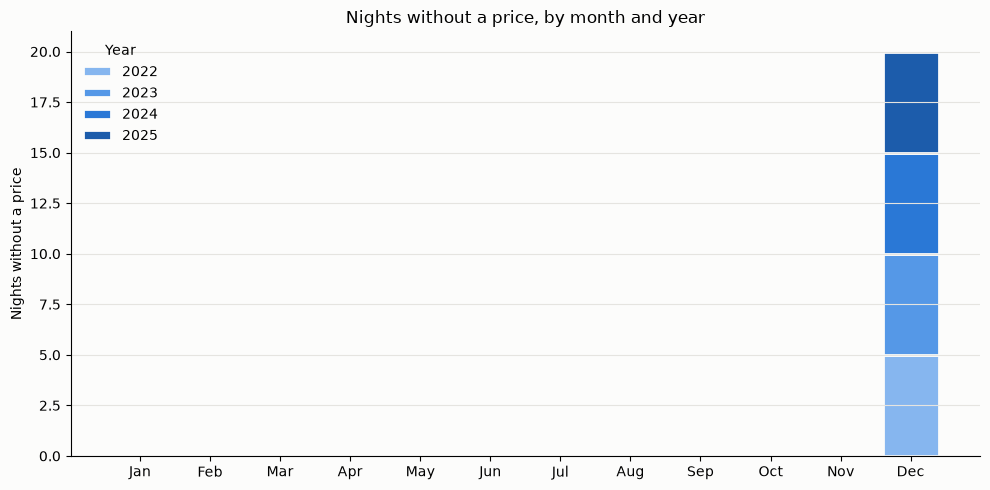

In [103]:
counts = pd.crosstab(missing.month, missing.year)
counts = counts.reindex(index=range(1, 13), columns=list(YEAR_COLORS), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5), facecolor=SURFACE)
stack_base = pd.Series(0, index=counts.index)
for year, color in YEAR_COLORS.items():
    ax.bar(
        counts.index,
        counts[year],
        bottom=stack_base,
        color=color,
        edgecolor=SURFACE,
        linewidth=2,
        label=year,
    )
    stack_base = stack_base + counts[year]

ax.set_xticks(range(1, 13))
ax.set_xticklabels(calendar.month_abbr[1:])
ax.set_ylabel("Nights without a price")
ax.set_title("Nights without a price, by month and year")
ax.legend(title="Year", frameon=False)
ax.set_facecolor(SURFACE)
ax.grid(axis="y", color=GRID)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

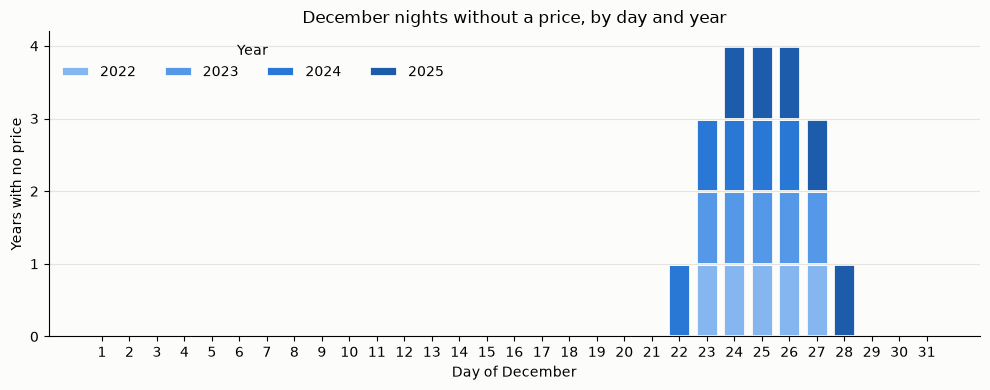

In [104]:
# Identify missing prices in December and plot them per day
december = missing[missing.month == 12]
dec_counts = pd.crosstab(december.day, december.year)
dec_years = [y for y in YEAR_COLORS if y != 2026]
dec_counts = dec_counts.reindex(index=range(1, 32), columns=dec_years, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4), facecolor=SURFACE)
stack_base = pd.Series(0, index=dec_counts.index)
for year in dec_years:
    ax.bar(
        dec_counts.index,
        dec_counts[year],
        bottom=stack_base,
        color=YEAR_COLORS[year],
        edgecolor=SURFACE,
        linewidth=2,
        label=year,
    )
    stack_base = stack_base + dec_counts[year]

ax.set_xticks(range(1, 32))
ax.set_yticks(range(0, 5))
ax.set_xlabel("Day of December")
ax.set_ylabel("Years with no price")
ax.set_title("December nights without a price, by day and year")
ax.legend(title="Year", frameon=False, ncol=4)
ax.set_facecolor(SURFACE)
ax.grid(axis="y", color=GRID)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

In [105]:
def empty_summary(frame, columns, date_col="stay_date", last_year=2025):
    """% of rows empty per year, overall, and the first date each column has data."""
    years = pd.to_datetime(frame[date_col]).dt.year
    frame = frame[years <= last_year]
    years = years[years <= last_year]

    summary = (frame[columns].isna().groupby(years).mean() * 100).T.round(1)
    summary.columns = [f"% empty {year}" for year in summary.columns]
    summary["% empty overall"] = (frame[columns].isna().mean() * 100).round(1)
    summary.insert(
        0,
        "date started",
        [frame.loc[frame[c].notna(), date_col].min() for c in columns],
    )
    return summary

In [106]:
CAPACITY = ["rooms_available", "rooms_blocked", "rooms_out_of_service", "waitlist"]
# Always known: computed from the date alone (room_type is always recorded).
CALENDAR = [
    "room_type",
    "day_of_week",
    "month",
    "weekend_flag",
    "week_of_year",
    "days_to_or_from_holiday",
    "long_weekend_flag",
    "day_of_month",
    "year",
]


async def load_capacity():
    stmt = (
        select(
            DailyPerformance.stay_date,
            DailyPerformance.rate,
            DailyPerformance.rooms_available,
            DailyPerformance.rooms_blocked,
            DailyPerformance.rooms_out_of_service,
            DailyPerformance.waitlist,
        )
        .join(RoomType, DailyPerformance.room_type_id == RoomType.id)
        .where(RoomType.hotel_id == HOTEL_ID)
    )
    async with async_session_factory() as session:
        result = await session.execute(stmt)
        return pd.DataFrame(result.all(), columns=list(result.keys()))


capacity = await load_capacity()  # noqa: F704
capacity["rate"] = pd.Series(capacity["rate"], dtype=float)
capacity["year"] = pd.to_datetime(capacity["stay_date"]).dt.year
priced_rows = capacity[(capacity["rate"] > 0) & (capacity["year"] <= 2025)]

capacity_summary = empty_summary(priced_rows, CAPACITY)

calendar_table = pd.DataFrame(
    {"stay_date": pd.to_datetime(priced_rows["stay_date"].unique())}
)
for name in CALENDAR:
    calendar_table[name] = 1.0  # placeholder: always known, computed from the date
calendar_summary = empty_summary(calendar_table, CALENDAR)

print(pd.concat([calendar_summary, capacity_summary]))

                                date started  % empty 2022  % empty 2023  \
room_type                2022-01-01 00:00:00           0.0           0.0   
day_of_week              2022-01-01 00:00:00           0.0           0.0   
month                    2022-01-01 00:00:00           0.0           0.0   
weekend_flag             2022-01-01 00:00:00           0.0           0.0   
week_of_year             2022-01-01 00:00:00           0.0           0.0   
days_to_or_from_holiday  2022-01-01 00:00:00           0.0           0.0   
long_weekend_flag        2022-01-01 00:00:00           0.0           0.0   
day_of_month             2022-01-01 00:00:00           0.0           0.0   
year                     2022-01-01 00:00:00           0.0           0.0   
rooms_available                   2022-01-01           0.0           0.0   
rooms_blocked                            NaN         100.0         100.0   
rooms_out_of_service                     NaN         100.0         100.0   
waitlist    

In [107]:
HORIZON_DAYS = 30  # we price a night 30 days ahead, so only use what we'd know then


async def load_bookings():
    stmt = select(
        Booking.book_ref,
        Booking.booked_at,
        Booking.arrival,
        Booking.departure,
        Booking.nights,
        Booking.rate_plan,
        Booking.market_segment,
        Booking.company_code,
        Booking.agent_code,
    ).where(Booking.hotel_id == HOTEL_ID)
    async with async_session_factory() as session:
        result = await session.execute(stmt)
        return pd.DataFrame(result.all(), columns=list(result.keys()))

In [108]:
def booking_features(bookings):
    """One row per night, from rooms booked at least HORIZON_DAYS before that night."""
    b = bookings.copy()
    b["booked_on"] = pd.to_datetime(b["booked_at"]).dt.normalize()
    b["arrival"] = pd.to_datetime(b["arrival"])
    b["departure"] = pd.to_datetime(b["departure"])

    # Rooms in the same booking share a reference, e.g. BK100014/1 and BK100014/2.
    b["booking"] = b["book_ref"].str.split("/").str[0]
    b["booking_rooms"] = b.groupby("booking")["book_ref"].transform("size")

    b["lead_days"] = (b["arrival"] - b["booked_on"]).dt.days
    b["advance"] = b["rate_plan"].str.startswith("ADV", na=False).astype(float)
    b["breakfast"] = b["rate_plan"].str.contains(r"(?:^|_)BB(?:_|$)", na=False)
    b["breakfast"] = b["breakfast"].astype(float)
    b["group"] = (b["booking_rooms"] >= 5).astype(float)
    b["non_leisure"] = (b["market_segment"].fillna("LEISURE") != "LEISURE").astype(
        float
    )
    b["has_company"] = b["company_code"].notna().astype(float)
    b["has_agent"] = b["agent_code"].notna().astype(float)

    # One row per room per night stayed (arrival up to, not including, departure).
    one_day = pd.Timedelta(days=1)
    b["stay_date"] = [
        pd.date_range(a, d - one_day)
        for a, d in zip(b["arrival"], b["departure"], strict=True)
    ]
    b = b.explode("stay_date")
    b["stay_date"] = pd.to_datetime(b["stay_date"])

    # Keep only what we would have known HORIZON_DAYS before that night.
    known = b["booked_on"] <= b["stay_date"] - pd.Timedelta(days=HORIZON_DAYS)
    b = b[known]

    return b.groupby("stay_date").agg(
        lead_time=("lead_days", "mean"),
        length_of_stay=("nights", "mean"),
        advance_share=("advance", "mean"),
        breakfast_share=("breakfast", "mean"),
        group_rooms=("group", "sum"),
        booking_pace=("book_ref", "size"),
        non_leisure_share=("non_leisure", "mean"),
        company_share=("has_company", "mean"),
        agent_share=("has_agent", "mean"),
    )

In [109]:
bookings = await load_bookings()  # noqa: F704
per_night = booking_features(bookings)

priced_nights = pd.DatetimeIndex(pd.to_datetime(priced_rows["stay_date"].unique()))
booking_table = per_night.reindex(priced_nights).rename_axis("stay_date").reset_index()

BOOKING = list(per_night.columns)
booking_summary = empty_summary(booking_table, BOOKING)
print(booking_summary)

                  date started  % empty 2022  % empty 2023  % empty 2024  \
lead_time           2022-02-03           9.2           0.0           0.0   
length_of_stay      2022-02-03           9.2           0.0           0.0   
advance_share       2022-02-03           9.2           0.0           0.0   
breakfast_share     2022-02-03           9.2           0.0           0.0   
group_rooms         2022-02-03           9.2           0.0           0.0   
booking_pace        2022-02-03           9.2           0.0           0.0   
non_leisure_share   2022-02-03           9.2           0.0           0.0   
company_share       2022-02-03           9.2           0.0           0.0   
agent_share         2022-02-03           9.2           0.0           0.0   

                   % empty 2025  % empty overall  
lead_time                   0.0              2.3  
length_of_stay              0.0              2.3  
advance_share               0.0              2.3  
breakfast_share             0.0    

In [110]:
async def load_cancellations():
    stmt = select(
        BookingCancellation.book_ref,
        BookingCancellation.cancelled_at,
        BookingCancellation.reason_code,
        BookingCancellation.arrival,
        BookingCancellation.departure,
    ).where(BookingCancellation.hotel_id == HOTEL_ID)
    async with async_session_factory() as session:
        result = await session.execute(stmt)
        return pd.DataFrame(result.all(), columns=list(result.keys()))


def cancellation_features(cancellations, per_night):
    """One row per night, from cancellations made at least HORIZON_DAYS before it.

    A no-show is only known on the arrival day, so it never counts here.
    """
    c = cancellations[cancellations["reason_code"] != "DUPLICATE"].copy()
    c["cancelled_on"] = pd.to_datetime(c["cancelled_at"]).dt.normalize()
    c["arrival"] = pd.to_datetime(c["arrival"])
    c["departure"] = pd.to_datetime(c["departure"])

    # Only stays that touch 2022-2025, to keep this small.
    touches = (c["departure"] >= pd.Timestamp("2022-01-01")) & (
        c["arrival"] <= pd.Timestamp("2025-12-31")
    )
    c = c[touches].copy()
    c["lead_days"] = (c["arrival"] - c["cancelled_on"]).dt.days

    # One row per cancelled room per night it would have stayed.
    one_day = pd.Timedelta(days=1)
    c["stay_date"] = [
        pd.date_range(a, d - one_day)
        for a, d in zip(c["arrival"], c["departure"], strict=True)
    ]
    c = c.explode("stay_date")
    c["stay_date"] = pd.to_datetime(c["stay_date"])

    # Keep only what we would have known HORIZON_DAYS before that night.
    known = c["cancelled_on"] <= c["stay_date"] - pd.Timedelta(days=HORIZON_DAYS)
    c = c[known]

    by_night = c.groupby("stay_date").agg(
        cancelled_rooms=("lead_days", "size"),
        cancellation_lead_time=("lead_days", "mean"),
    )
    joined = by_night.join(per_night[["booking_pace"]], how="outer")

    # Rate = cancelled rooms / (cancelled rooms + rooms still booked), both known
    # HORIZON_DAYS ahead. Blank when there was no activity at all.
    cancelled = joined["cancelled_rooms"].fillna(0)
    booked = joined["booking_pace"].fillna(0)
    joined["cancellation_rate"] = (cancelled / (cancelled + booked)).where(
        cancelled + booked > 0
    )
    return joined[["cancellation_rate", "cancellation_lead_time"]]

In [111]:
cancellations = await load_cancellations()  # noqa: F704
cancel_per_night = cancellation_features(cancellations, per_night)

cancel_table = (
    cancel_per_night.reindex(priced_nights).rename_axis("stay_date").reset_index()
)

CANCELLATION = list(cancel_per_night.columns)
cancellation_summary = empty_summary(cancel_table, CANCELLATION)
print(cancellation_summary)

                       date started  % empty 2022  % empty 2023  % empty 2024  \
cancellation_rate        2022-01-01           0.0           0.0           0.0   
cancellation_lead_time   2022-01-01           0.0           0.0           0.0   

                        % empty 2025  % empty overall  
cancellation_rate                0.0              0.0  
cancellation_lead_time           0.0              0.0  


In [112]:
# Rule: screen only nights from the first night the booking data covers.
SCREEN_START = per_night.index.min()
booking_screen = booking_table[booking_table["stay_date"] >= SCREEN_START]
print(
    f"Screening starts {SCREEN_START.date()}, "
    f"{len(booking_table) - len(booking_screen)} nights dropped"
)
print(empty_summary(booking_screen, BOOKING))

Screening starts 2022-02-03, 33 nights dropped
                  date started  % empty 2022  % empty 2023  % empty 2024  \
lead_time           2022-02-03           0.0           0.0           0.0   
length_of_stay      2022-02-03           0.0           0.0           0.0   
advance_share       2022-02-03           0.0           0.0           0.0   
breakfast_share     2022-02-03           0.0           0.0           0.0   
group_rooms         2022-02-03           0.0           0.0           0.0   
booking_pace        2022-02-03           0.0           0.0           0.0   
non_leisure_share   2022-02-03           0.0           0.0           0.0   
company_share       2022-02-03           0.0           0.0           0.0   
agent_share         2022-02-03           0.0           0.0           0.0   

                   % empty 2025  % empty overall  
lead_time                   0.0              0.0  
length_of_stay              0.0              0.0  
advance_share               0.0        

In [113]:
no_cancel = cancel_table["cancellation_lead_time"].isna().sum()
zero_rate = (cancel_table["cancellation_rate"] == 0).sum()
print(f"Nights with no cancellations known 30 days ahead: {no_cancel}")
print(f"Nights where the rate is exactly 0: {zero_rate}")
print(cancel_table.head(40).to_string())

Nights with no cancellations known 30 days ahead: 0
Nights where the rate is exactly 0: 0
    stay_date  cancellation_rate  cancellation_lead_time
0  2022-01-01           1.000000               46.950000
1  2022-01-02           1.000000               47.785714
2  2022-01-03           1.000000               65.166667
3  2022-01-04           1.000000               61.692308
4  2022-01-05           1.000000               83.384615
5  2022-01-06           1.000000               65.636364
6  2022-01-07           1.000000               64.818182
7  2022-01-08           1.000000               48.214286
8  2022-01-09           1.000000               54.000000
9  2022-01-10           1.000000               45.000000
10 2022-01-11           1.000000               64.333333
11 2022-01-12           1.000000               67.555556
12 2022-01-13           1.000000               89.416667
13 2022-01-14           1.000000               73.916667
14 2022-01-15           1.000000               89.00000

In [114]:
screen = cancel_table[cancel_table["stay_date"] >= SCREEN_START]
by_month = (
    screen.groupby(screen["stay_date"].dt.to_period("M"))["cancellation_rate"]
    .mean()
    .round(2)
)
print(by_month.head(14).to_string())
print(by_month.groupby(by_month.index.year).mean().round(2))

stay_date
2022-02    0.68
2022-03    0.50
2022-04    0.43
2022-05    0.40
2022-06    0.36
2022-07    0.39
2022-08    0.45
2022-09    0.43
2022-10    0.47
2022-11    0.49
2022-12    0.52
2023-01    0.46
2023-02    0.45
2023-03    0.40
Freq: M
stay_date
2022    0.47
2023    0.45
2024    0.58
2025    0.59
Name: cancellation_rate, dtype: float64


In [115]:
THRESHOLD = 25  # a feature with more than this % empty overall is flagged

all_features = pd.concat(
    [calendar_summary, capacity_summary, booking_summary, cancellation_summary]
)
over_25 = all_features[all_features["% empty overall"] > THRESHOLD].copy()
over_25["over by"] = (over_25["% empty overall"] - THRESHOLD).round(1)
over_25 = over_25.sort_values("% empty overall", ascending=False)

print(all_features)
print(f"\nOver {THRESHOLD}% empty (emptiest first):")
print(over_25)

                                date started  % empty 2022  % empty 2023  \
room_type                2022-01-01 00:00:00           0.0           0.0   
day_of_week              2022-01-01 00:00:00           0.0           0.0   
month                    2022-01-01 00:00:00           0.0           0.0   
weekend_flag             2022-01-01 00:00:00           0.0           0.0   
week_of_year             2022-01-01 00:00:00           0.0           0.0   
days_to_or_from_holiday  2022-01-01 00:00:00           0.0           0.0   
long_weekend_flag        2022-01-01 00:00:00           0.0           0.0   
day_of_month             2022-01-01 00:00:00           0.0           0.0   
year                     2022-01-01 00:00:00           0.0           0.0   
rooms_available                   2022-01-01           0.0           0.0   
rooms_blocked                            NaN         100.0         100.0   
rooms_out_of_service                     NaN         100.0         100.0   
waitlist    